# Reproducing the household NAR distribution figure

This notebook reproduces the distribution of each nutrient's adequacy
ratio (NAR) across actual surveyed households - what households actually
produce today, divided by what they need - showing which nutrients tend
to fall short and by how much, and how that compares to the household's
average NAR across all nutrients.

Self-contained: only `data/` in this repository is needed (no `functions.py`
dependency - this figure is derived directly from household production and
requirement data, not from the land-use optimization model).

For interactive exploration of the land-use model itself, see the
companion dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Nutrients found to be "mostly falling short" across households - drawn in orange
# with a peak label; everything else in gray.
FALLING_SHORT = ["vit.a", "ca", "vit.b12", "vit.c"]
COLOR_ORANGE = "#d95f02"
COLOR_GRAY = "#b8c0c4"
COLOR_MEAN = "black"

## 2. Compute household NAR

NAR (0-100) per nutrient per household = actual production / requirement,
capped at 100%. South Africa excluded (sole country in its macro-area,
treated as an outlier throughout this analysis); fat dropped (not
considered in this analysis).

In [2]:
df_prod = pd.read_csv("data/original/hh_full_production_02.08.csv")
df_req = pd.read_csv("data/original/CLEAN_nut_requirements_HH_10.12.24.csv")
df_country = pd.read_csv("data/original/FINAL_results_10-12-2024.csv", usecols=["id_unique", "id_country"])

df_prod = df_prod.drop(columns=[c for c in df_prod.columns if c.startswith("Unnamed")]).set_index("id_unique")
df_req = df_req.drop(columns=[c for c in df_req.columns if c.startswith("Unnamed")]).set_index("id_unique")
# CLEAN_nut_requirements_HH uses "protein"/"carbs"; hh_full_production uses "prot"/"carb" -
# pandas division aligns by column NAME, so these must be renamed to match or those two
# columns would silently come out all-NaN.
df_req = df_req.rename(columns={"protein": "prot", "carbs": "carb"})

common_ids = df_prod.index.intersection(df_req.index)
nar = (df_prod.loc[common_ids] / df_req.loc[common_ids]).clip(upper=1.0) * 100
nar = nar.drop(columns=["fat"])

nar = nar.merge(df_country.set_index("id_unique"), left_index=True, right_index=True, how="left")
nar = nar[nar["id_country"] != "za"].drop(columns=["id_country"])
print(f"{len(nar)} households after excluding South Africa")
nar.describe().T.round(1)

26856 households after excluding South Africa


,count,mean,std,min,25%,50%,75%,max
kcal,26823.0,55.0,40.2,0.0,14.2,53.0,100.0,100.0
prot,26823.0,64.2,39.4,0.0,22.8,84.9,100.0,100.0
carb,26809.0,71.7,38.8,0.0,37.0,100.0,100.0,100.0
ca,26823.0,29.9,35.7,0.0,3.1,12.6,45.5,100.0
fe,26823.0,65.8,39.7,0.0,24.0,97.8,100.0,100.0
mg,26823.0,73.5,38.1,0.0,41.5,100.0,100.0,100.0
p,26823.0,68.5,38.8,0.0,29.6,100.0,100.0,100.0
k,26823.0,54.5,39.9,0.0,14.4,50.6,100.0,100.0
zn,26823.0,68.7,38.3,0.0,30.6,100.0,100.0,100.0
vit.a,26793.0,22.8,34.1,0.0,0.6,5.3,26.7,100.0


## 3. Figure

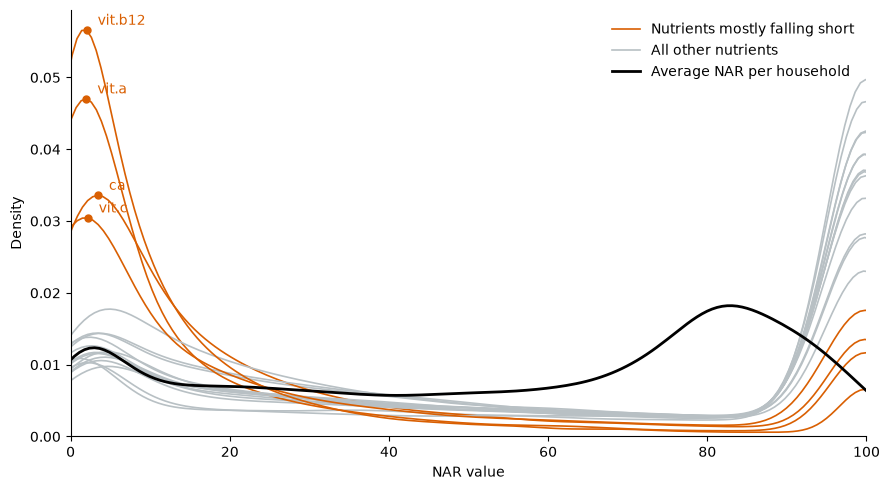

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

peak_labels = []
for nutrient in nar.columns:
    color = COLOR_ORANGE if nutrient in FALLING_SHORT else COLOR_GRAY
    sns.kdeplot(nar[nutrient].dropna(), color=color, linewidth=1.2, ax=ax)
    if nutrient in FALLING_SHORT:
        xdata, ydata = ax.lines[-1].get_data()
        i = ydata.argmax()
        peak_labels.append((xdata[i], ydata[i], nutrient))

household_mean = nar.mean(axis=1)
sns.kdeplot(household_mean.dropna(), color=COLOR_MEAN, linewidth=2.0, ax=ax)

for x, y, text in peak_labels:
    ax.scatter([x], [y], color=COLOR_ORANGE, s=25, zorder=5)
    ax.annotate(text, xy=(x, y), xytext=(8, 4), textcoords="offset points", fontsize=10, color=COLOR_ORANGE)

handles = [
    Line2D([0], [0], color=COLOR_ORANGE, lw=1.2, label="Nutrients mostly falling short"),
    Line2D([0], [0], color=COLOR_GRAY, lw=1.2, label="All other nutrients"),
    Line2D([0], [0], color=COLOR_MEAN, lw=2.0, label="Average NAR per household"),
]
ax.legend(handles=handles, loc="upper right", frameon=False)
ax.set_xlabel("NAR value")
ax.set_ylabel("Density")
ax.set_xlim(0, 100)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## Notes

- For interactive exploration of the land-use optimization model itself -
  adjustable nutrient constraints, country selection, household
  composition - see the companion dashboard:
  **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
